# Tugas Praktikum #2
## Pemrosesan Paralel

**Nama:** Afelia Nasyifa  
**NIM:** 2411513010  
**Kelas:** B

---
## 1. Bank Account Race Condition

Pada percobaan ini digunakan 10 thread yang masing-masing melakukan operasi tarik Rp1 dan setor Rp1 sebanyak 10.000 kali. Percobaan pertama dilakukan tanpa `Lock`, kemudian dibandingkan dengan percobaan menggunakan `threading.Lock()`.

In [2]:
import threading

saldo = 1_000_000

def transaksi():
    global saldo
    
    for _ in range(10_000):
        saldo -= 1
        saldo += 1

jumlah_thread = 10

threads = [
    threading.Thread(target=transaksi)
    for _ in range(jumlah_thread)
]

for t in threads:
    t.start()

for t in threads:
    t.join()

print("Saldo awal  :", 1_000_000)
print("Saldo akhir :", saldo)
print("Sesuai      :", "YA" if saldo == 1_000_000 else "TIDAK")

Saldo awal  : 1000000
Saldo akhir : 1000000
Sesuai      : YA


### Analisis tanpa Lock

Secara perhitungan, setiap thread melakukan tarik Rp1 lalu setor kembali Rp1, sehingga saldo seharusnya kembali ke Rp1.000.000.

Namun, operasi terhadap variabel `saldo` dilakukan oleh beberapa thread tanpa pengamanan. Pada CPython dengan GIL, hasil race condition pada percobaan sederhana seperti ini tidak selalu terlihat sehingga saldo bisa saja tetap Rp1.000.000. Jadi, hasil tersebut bukan berarti akses terhadap data bersama sudah aman. Masalahnya tetap ada ketika beberapa thread mengubah shared state tanpa sinkronisasi.

In [3]:
import threading

saldo = 1_000_000
lock = threading.Lock()

def transaksi_dengan_lock():
    global saldo
    
    for _ in range(10_000):
        with lock:
            saldo -= 1
            saldo += 1

threads = [
    threading.Thread(target=transaksi_dengan_lock)
    for _ in range(10)
]

for t in threads:
    t.start()

for t in threads:
    t.join()

print("Saldo awal  :", 1_000_000)
print("Saldo akhir :", saldo)
print("Sesuai      :", "YA" if saldo == 1_000_000 else "TIDAK")

Saldo awal  : 1000000
Saldo akhir : 1000000
Sesuai      : YA


## 2. Producer-Consumer dengan Banyak Consumer

Pada percobaan ini dibuat satu producer dan tiga consumer. Producer memasukkan beberapa data ke dalam `queue.Queue`, sedangkan consumer mengambil dan memproses data tersebut secara bersamaan.

Setelah seluruh data selesai dimasukkan, producer mengirimkan sinyal `None` sebanyak jumlah consumer. Sinyal tersebut digunakan untuk memberitahu setiap consumer bahwa tidak ada pekerjaan lagi.

In [4]:
import threading
import queue
import time
import random

q = queue.Queue()

JUMLAH_DATA = 15
JUMLAH_CONSUMER = 3


def producer():
    for i in range(1, JUMLAH_DATA + 1):
        data = f"Data-{i}"
        q.put(data)
        print(f"[Producer] memasukkan {data}")
        time.sleep(random.uniform(0.05, 0.15))

    # Satu None untuk masing-masing consumer
    for _ in range(JUMLAH_CONSUMER):
        q.put(None)

    print("[Producer] selesai")


def consumer(nama):
    while True:
        data = q.get()

        try:
            if data is None:
                print(f"[{nama}] menerima sinyal selesai")
                return

            print(f"[{nama}] memproses {data}")
            time.sleep(random.uniform(0.1, 0.25))

        finally:
            q.task_done()


producer_thread = threading.Thread(target=producer)

consumer_threads = [
    threading.Thread(target=consumer, args=(f"Consumer-{i}",))
    for i in range(1, JUMLAH_CONSUMER + 1)
]

# Jalankan consumer
for t in consumer_threads:
    t.start()

# Jalankan producer
producer_thread.start()

# Tunggu producer selesai memasukkan seluruh data
producer_thread.join()

# Tunggu seluruh data dalam queue selesai diproses
q.join()

# Tunggu seluruh consumer benar-benar berhenti
for t in consumer_threads:
    t.join()

print("\nSemua producer dan consumer sudah selesai.")

[Producer] memasukkan Data-1
[Consumer-1] memproses Data-1
[Producer] memasukkan Data-2
[Consumer-2] memproses Data-2
[Producer] memasukkan Data-3
[Consumer-3] memproses Data-3
[Producer] memasukkan Data-4[Consumer-1] memproses Data-4

[Producer] memasukkan Data-5
[Consumer-2] memproses Data-5
[Producer] memasukkan Data-6
[Consumer-3] memproses Data-6
[Producer] memasukkan Data-7[Consumer-1] memproses Data-7

[Producer] memasukkan Data-8
[Consumer-2] memproses Data-8
[Producer] memasukkan Data-9
[Consumer-3] memproses Data-9
[Producer] memasukkan Data-10[Consumer-1] memproses Data-10

[Producer] memasukkan Data-11
[Consumer-2] memproses Data-11
[Producer] memasukkan Data-12[Consumer-3] memproses Data-12

[Producer] memasukkan Data-13
[Consumer-1] memproses Data-13
[Producer] memasukkan Data-14
[Consumer-2] memproses Data-14
[Producer] memasukkan Data-15[Consumer-3] memproses Data-15

[Producer] selesai[Consumer-1] menerima sinyal selesai[Consumer-2] menerima sinyal selesai


[Consumer-

### Penjelasan

`queue.Queue` digunakan sebagai tempat pertukaran data antara producer dan consumer. Producer tidak perlu mengetahui consumer mana yang akan mengambil data karena pembagian pekerjaan dilakukan oleh queue.

Bagian pentingnya adalah sinyal `None`. Karena jumlah consumer ada tiga, producer memasukkan tiga `None` setelah seluruh data selesai diproduksi. Setiap consumer berhenti ketika mengambil satu `None`.

`q.task_done()` digunakan untuk menandai bahwa satu item yang diambil dari queue sudah selesai diproses. Kemudian `q.join()` memastikan program menunggu sampai seluruh isi queue benar-benar selesai.

## 3. Eksperimen ThreadPoolExecutor

Percobaan ini menggunakan 50 file dengan waktu akses yang dibuat berbeda-beda untuk mensimulasikan pekerjaan I/O-bound. Pengujian dilakukan menggunakan beberapa nilai `max_workers`, yaitu 2, 4, 8, dan 16.

In [1]:
from concurrent.futures import ThreadPoolExecutor, as_completed
import time
import random
import matplotlib.pyplot as plt

# Membuat 50 file simulasi
random.seed(42)

daftar_file = [f"file_{i}.dat" for i in range(50)]

# Waktu tunggu masing-masing file
latensi_simulasi = {
    nama_file: random.uniform(0.3, 0.8)
    for nama_file in daftar_file
}


def download_file(nama_file):
    # Simulasi menunggu proses I/O
    durasi = latensi_simulasi[nama_file]
    time.sleep(durasi)

    ukuran_kb = round(durasi * 1000)

    return nama_file, ukuran_kb


def jalankan_pool(max_workers):
    start = time.perf_counter()
    hasil = []

    with ThreadPoolExecutor(max_workers=max_workers) as executor:
        futures = [
            executor.submit(download_file, nama_file)
            for nama_file in daftar_file
        ]

        for future in as_completed(futures):
            hasil_download = future.result()
            hasil.append(hasil_download)

    waktu = time.perf_counter() - start

    return waktu, hasil


# Pengujian
daftar_workers = [2, 4, 8, 16]
hasil_waktu = []

for workers in daftar_workers:
    waktu, hasil = jalankan_pool(workers)
    hasil_waktu.append(waktu)

    print(f"max_workers = {workers}")
    print(f"Jumlah file = {len(hasil)}")
    print(f"Waktu       = {waktu:.2f} detik")
    print("-" * 35)

max_workers = 2
Jumlah file = 50
Waktu       = 13.27 detik
-----------------------------------
max_workers = 4
Jumlah file = 50
Waktu       = 6.81 detik
-----------------------------------
max_workers = 8
Jumlah file = 50
Waktu       = 3.59 detik
-----------------------------------
max_workers = 16
Jumlah file = 50
Waktu       = 1.98 detik
-----------------------------------


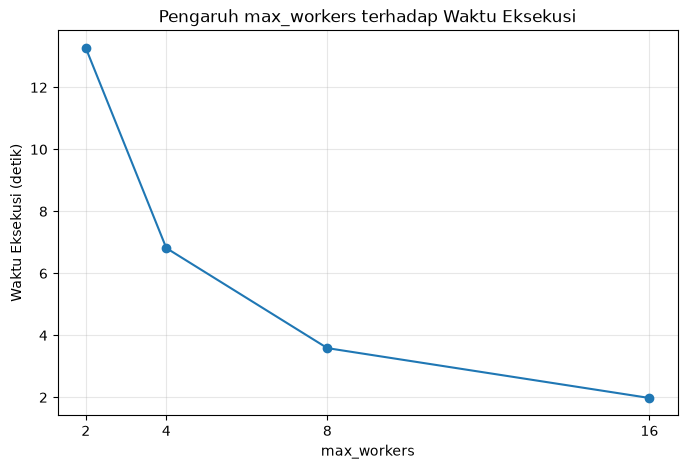

In [2]:
plt.figure(figsize=(8, 5))

plt.plot(
    daftar_workers,
    hasil_waktu,
    marker="o"
)

plt.xlabel("max_workers")
plt.ylabel("Waktu Eksekusi (detik)")
plt.title("Pengaruh max_workers terhadap Waktu Eksekusi")
plt.xticks(daftar_workers)
plt.grid(True, alpha=0.3)

plt.show()

In [3]:
print("Ringkasan hasil:")
print()

for workers, waktu in zip(daftar_workers, hasil_waktu):
    print(f"max_workers = {workers:2d} -> {waktu:.2f} detik")

Ringkasan hasil:

max_workers =  2 -> 13.27 detik
max_workers =  4 -> 6.81 detik
max_workers =  8 -> 3.59 detik
max_workers = 16 -> 1.98 detik


### Analisis

Penambahan `max_workers` tidak selalu membuat waktu eksekusi terus turun. Pada awalnya, jumlah worker yang lebih banyak membuat beberapa pekerjaan I/O dapat berlangsung bersamaan sehingga waktu total menjadi lebih pendek.

Namun, setelah jumlah worker cukup besar, keuntungan penambahan thread mulai mengecil. Hal ini terjadi karena pekerjaan yang dijalankan tetap memiliki waktu tunggu dan sistem juga harus mengatur lebih banyak thread. Ketika worker sudah lebih banyak daripada tingkat paralelisme yang efektif, thread tambahan tidak lagi memberikan peningkatan yang sebanding.

Kondisi tersebut disebut titik jenuh. Jadi, `max_workers` sebaiknya disesuaikan dengan karakter pekerjaan dan kondisi sistem, bukan sekadar dibuat sebesar mungkin.

## 4. Refleksi Singkat

Threading Python lebih membantu ketika program banyak menghabiskan waktu untuk menunggu I/O. Contohnya aplikasi chat yang harus menangani banyak koneksi pengguna. Saat satu koneksi sedang menunggu data masuk, thread lain masih dapat mengerjakan koneksi yang berbeda sehingga waktu tunggu tidak sepenuhnya terbuang.

Sebaliknya, threading kurang cocok untuk pekerjaan CPU-bound seperti melakukan kompresi banyak gambar beresolusi tinggi secara bersamaan. Beban utamanya berada pada proses komputasi sehingga GIL dapat membatasi eksekusi bytecode Python secara paralel. Untuk kasus seperti ini, multiprocessing lebih sesuai karena pekerjaan dapat dibagi ke beberapa process yang berjalan pada core CPU berbeda.

Jadi, pemilihan threading atau multiprocessing sebaiknya melihat jenis pekerjaan terlebih dahulu, bukan hanya jumlah tugas yang akan dijalankan.